<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Pure_Elastic_Example_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

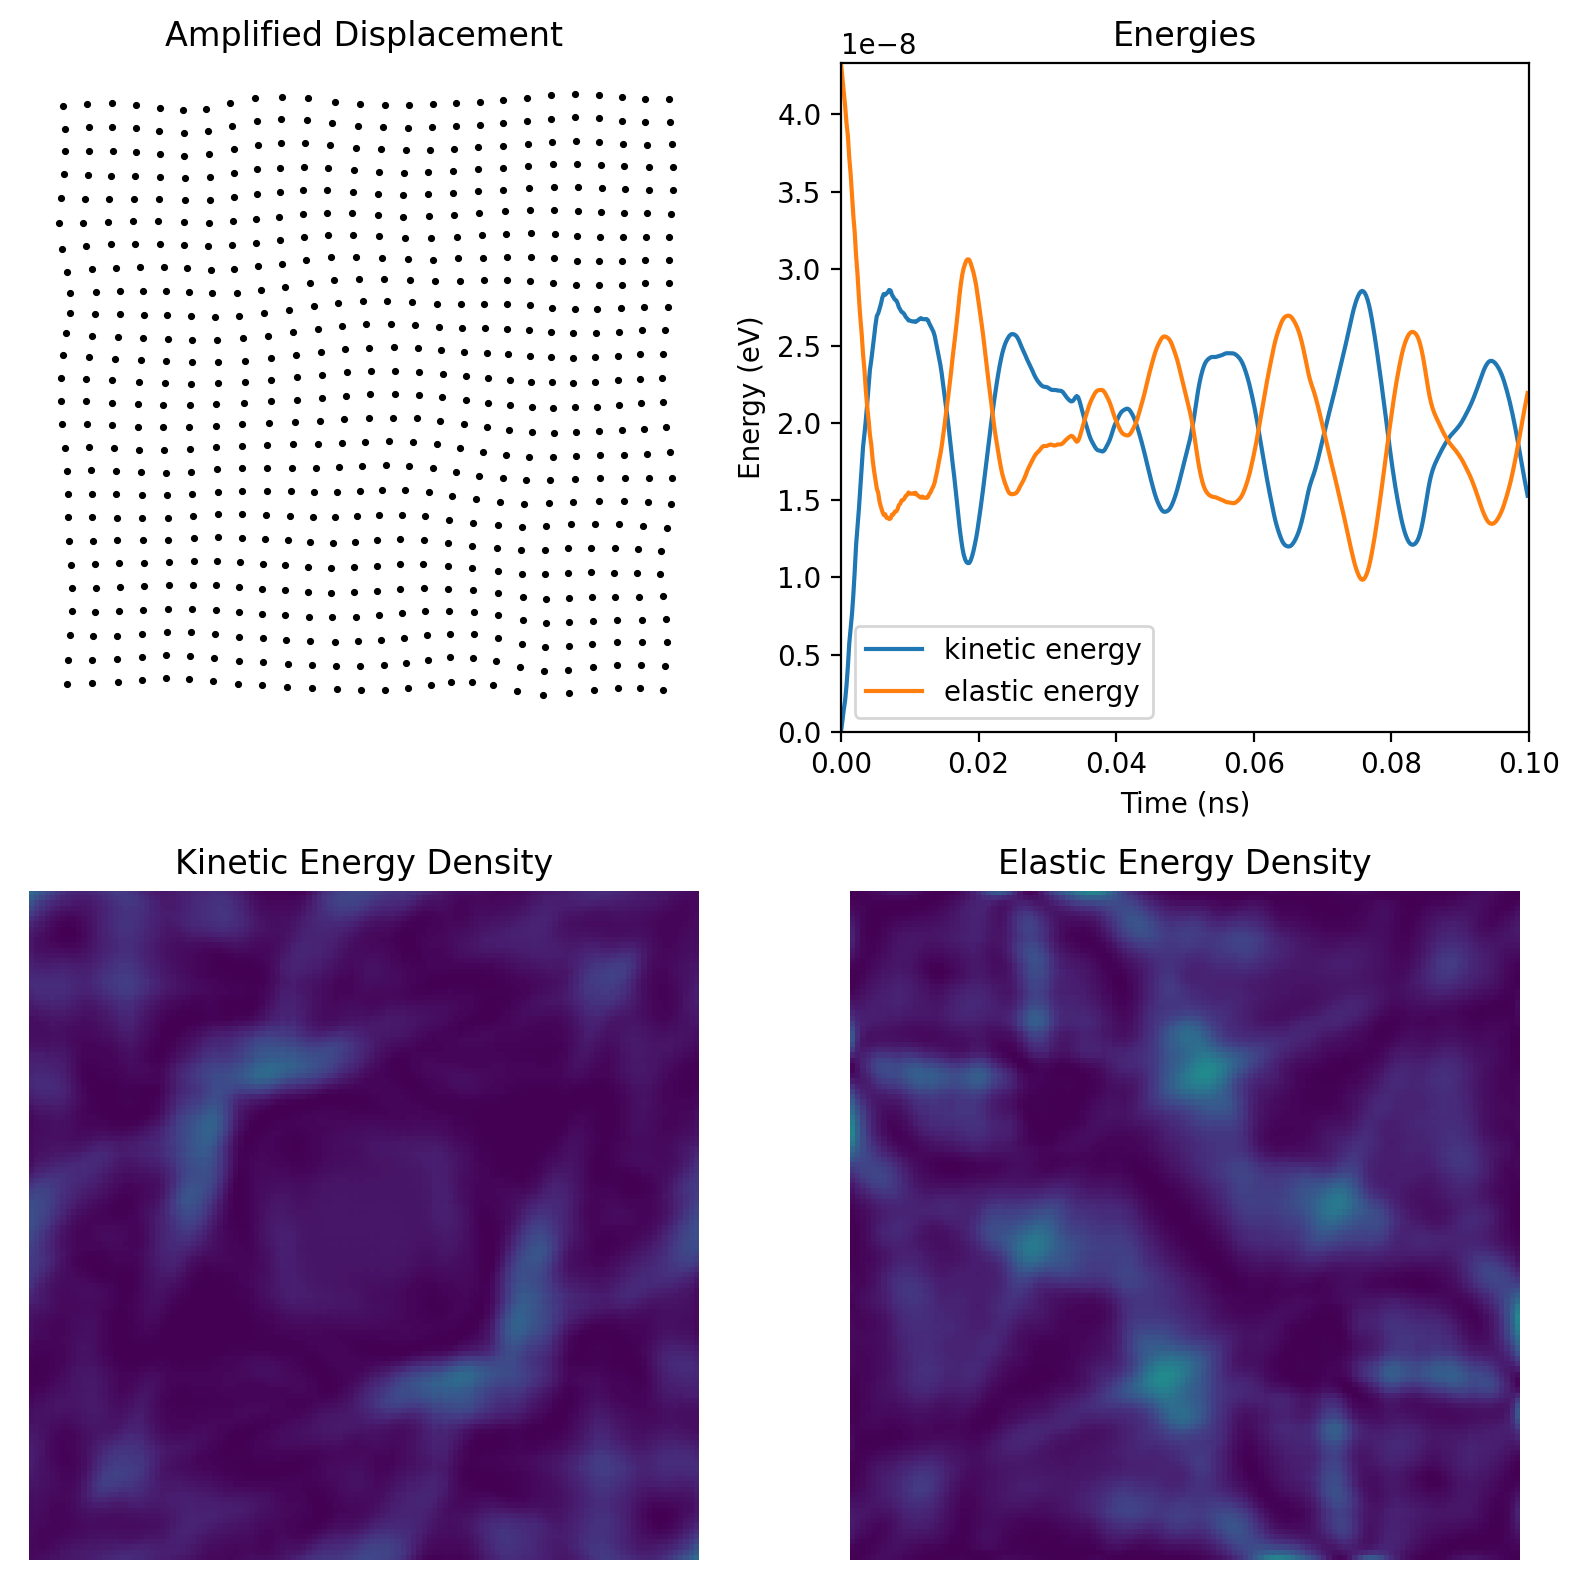

In [3]:
"""This example creates an elastic magnet without any magnetization.
It then shows an animation of the displacement and kinetic and potential energy."""

import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util.config import gaussian_spherical_IP
from mumaxplus.util.formulary import Rayleigh_damping_coefficients

plt.rcParams["figure.dpi"] = 200

J_to_eV = 6.24150907e18

frames = 500
skip = 5
u_scale = 1e7  # amplification of displacement

def displacement_to_scatter_data(magnet, scale, skip):
    """takes magnet.elastic_displacement.eval() array and turns it into an array
    of positions usable by plt.scatter().set_offsets"""

    u = magnet.elastic_displacement.eval()  # ((ux, uy, uz), Z, Y, X)
    coords = magnet.elastic_displacement.meshgrid + scale*u  # absolute positions amplified
    return  np.transpose(coords[:2, 0, ::skip, ::skip].reshape(2, -1))  # to (X*Y, 2)


# figures
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8, 8))
(ax1, ax2), (ax3, ax4) = axes
kinetic, = ax2.plot([], [], label="kinetic energy")
elastic, = ax2.plot([], [], label="elastic energy")

ax1.set_axis_off()
ax1.set_title("Amplified Displacement")

ax2.set_title("Energies")
ax2.set_xlabel("Time (ns)")
ax2.set_ylabel("Energy (eV)")
ax2.legend(loc="lower left")

ax3.set_axis_off()
ax3.set_title("Kinetic Energy Density")

ax4.set_axis_off()
ax4.set_title("Elastic Energy Density")

# magnet parameters
length, width, thickness = 200e-9, 200e-9, 20e-9
nx, ny, nz = 128, 128, 1
cx, cy, cz = length/nx, width/ny, thickness/nz
cellsize = (cx, cy, cz)

grid = Grid((nx, ny, nz))
# uncomment for PBC
world = World(cellsize)  # , mastergrid=grid, pbc_repetitions=(1,1,1))
magnet = Ferromagnet(world, grid)

# elasticity parameters
magnet.enable_elastodynamics = True

magnet.msat = 0
rho = 8e3
magnet.rho = rho
C11, C44, C12 = 283e9, 58e9, 166e9
magnet.C11, magnet.C44, magnet.C12 = C11, C44, C12

# --------------------
"""Add Rayleigh damping

The stiffness part of Rayleigh damping is automatically enabled by default via
the `Magnet.stiffness_damping` property. That Parameter is ignored when any part
of the viscosity tensor is set, like we explicitly do here in this example.
"""

# lowest relevant frequency has a wavelength similar to the length of the system
lowest_freq = np.sqrt(min(C11, C44) / rho) / (2 * max(length, width))
# highest relevant frequency has a wavelength of a few cells
highest_freq = np.sqrt(max(C11, C44) / rho) / (4 * min(cx, cy))
damping_ratio = 0.01  # 1%

mass_coef, stiffness_coef = Rayleigh_damping_coefficients(lowest_freq, damping_ratio,
                                                          highest_freq, damping_ratio)
# mass damping with phenomenological damping
eta = mass_coef * rho
magnet.eta = eta

# stiffness damping with viscosity
eta11, eta44, eta12 = stiffness_coef * C11, stiffness_coef * C44, stiffness_coef * C12
magnet.eta11, magnet.eta44, magnet.eta12 = eta11, eta44, eta12
# --------------------

magnet.elastic_displacement = gaussian_spherical_IP(
        magnet.center, 1e-15, np.pi/5, length/4, width/4)

# manually remove average displacement
u = magnet.elastic_displacement.eval()
u_avg = magnet.elastic_displacement.average()
for i in range(3):
    u[i, ...] -= u_avg[i]
magnet.elastic_displacement = u

# adaptive time stepping does not work for magnetoelastics
world.timesolver.adaptive_timestep = False
world.timesolver.timestep = 1e-13

# simulation
time = np.linspace(0, 1e-10, 500)
energies = {"E_kin": lambda : magnet.kinetic_energy.eval()*J_to_eV,
            "E_el": lambda : magnet.elastic_energy.eval()*J_to_eV,
            "E_kin_dens": lambda : magnet.kinetic_energy_density.eval(),
            "E_el_dens": lambda : magnet.elastic_energy_density.eval(),
            "disp": lambda : displacement_to_scatter_data(magnet, u_scale, skip)}
output = world.timesolver.solve(time, energies)

# animation setup
offsets = output["disp"][0]
u_scatter = ax1.scatter(offsets, offsets, s=10, c="black", marker=".")

t = time*1e9
ax2.set_xlim(min(t), max(t))  # Set x-axis limits based on time
ax2.set_ylim(min(min(output["E_kin"]), min(output["E_el"])),
            max(max(output["E_kin"]), max(output["E_el"])))

kin_dens = ax3.imshow(np.transpose(output["E_kin_dens"][0][0,0,...]), origin="lower",
                      vmin=0, vmax=np.max(output["E_el_dens"]))
el_dens = ax4.imshow(np.transpose(output["E_el_dens"][0][0,0,...]), origin="lower",
                     vmin=0, vmax=np.max(output["E_el_dens"]))


plt.tight_layout()

def update(i):
    j = int(i*len(t)/frames)
    kinetic.set_data(t[:j], output["E_kin"][:j])
    elastic.set_data(t[:j], output["E_el"][:j])
    u_scatter.set_offsets(output["disp"][j])
    kin_dens.set_array(np.transpose(output["E_kin_dens"][j][0,0,...]))
    el_dens.set_array(np.transpose(output["E_el_dens"][j][0,0,...]))
    return kinetic, elastic, u_scatter

# animation
animation_fig = animation.FuncAnimation(fig, update, frames=frames, interval=40, blit=True)
animation_fig.save("elastic.mp4")